# RSNA Knee Abnormality Detection — Step 1: labels from the reports

Self-contained. Nothing to upload, no API key, no extra datasets.

**Setup before you run:**
1. `+ Add Input` → the competition **RSNA Knee Abnormality Detection**
2. **Settings → Internet → ON**
3. Run cells top to bottom.

Model calls are billed to your **Kaggle AI quota** ($10/day, $100/month), the one
under your avatar → *Your Kaggle Quota* → AI. No API key is involved; the quota is
tied to your account and only reachable from inside a Kaggle notebook.

**What this produces:** `/kaggle/working/train_targets.csv` — every training study
with 12 label columns, gold where the organisers provided them and report-derived
everywhere else, `NaN` where the model would not commit. Save a version, then add
this notebook's *output* as an input to your training notebook.

## 0 · Setup

In [1]:
import os, sys, re, glob, json, time, random, threading, subprocess
from dataclasses import dataclass, fields as dc_fields, asdict, is_dataclass
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd

DATA_DIR = "/kaggle/input/competitions/rsna-knee-abnormality-detection"
WORK     = "/kaggle/working"
OUTDIR   = os.path.join(WORK, "labels")
os.makedirs(OUTDIR, exist_ok=True)

assert os.path.isdir(DATA_DIR), (
    f"{DATA_DIR} not found -- use '+ Add Input' to attach the competition dataset. "
    f"Present: {os.listdir('/kaggle/input') if os.path.isdir('/kaggle/input') else 'nothing'}"
)
print("competition files:", sorted(os.listdir(DATA_DIR)))

competition files: ['sample_submission.csv', 'test.csv', 'test_series', 'test_series.csv', 'train.csv', 'train_series', 'train_series.csv']


### Authenticating to the model proxy

`kbench.llms` is built from environment variables that `kaggle benchmarks auth`
writes into a `.env` file. From the SDK source:

```python
def is_configured():
    return "MODEL_PROXY_URL" in os.environ and "MODEL_PROXY_API_KEY" in os.environ
```

If those are missing, `import kaggle_benchmarks` still succeeds but `llms` is `{}`
and `llm` is a stand-in that raises as soon as you call it. **This is where your
Kaggle API token is used** — the CLI authenticates with it and exchanges it for
short-lived model-proxy credentials.

Order matters: authenticate *before* importing the SDK, because the registry is
built once, at import.

In [2]:
# protobuf: BOTH bounds matter. >=5.29.6 clears the gencode mismatch; <6 is
# required by kaggle-benchmarks itself and by grpcio-tools, ydf,
# google-ai-generativelanguage and the google-cloud-* stack. Plain
# "protobuf>=5.29.6" resolves to 7.x and breaks all of them.
!pip install -q "protobuf>=5.29.6,<6" kaggle_benchmarks

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 320.5/320.5 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.6/136.6 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.7/73.7 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 MB 37.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.39.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.


In [3]:
!pip install -q --upgrade kaggle
print()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 262.5/262.5 kB 7.1 MB/s eta 0:00:00



In [4]:
# Credential lookup order, straight from kagglesdk/kaggle_env.py:
#   1. in a Kaggle notebook: the file named by $KAGGLE_API_V1_TOKEN  <- usually automatic
#   2. $KAGGLE_API_TOKEN            (the token string itself, or a path to it)
#   3. ~/.kaggle/access_token       (new-style token)
#   4. ~/.kaggle/kaggle.json  or  $KAGGLE_USERNAME + $KAGGLE_KEY   (legacy)
def find_kaggle_creds():
    v1 = os.environ.get("KAGGLE_API_V1_TOKEN")
    if v1 and os.path.exists(v1):
        return f"notebook token ($KAGGLE_API_V1_TOKEN -> {v1})"
    if os.environ.get("KAGGLE_API_TOKEN"):
        return "$KAGGLE_API_TOKEN"
    for f in ("~/.kaggle/access_token", "~/.kaggle/access_token.txt",
              "~/.kaggle/kaggle.json"):
        if os.path.exists(os.path.expanduser(f)):
            return f
    if os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"):
        return "$KAGGLE_USERNAME + $KAGGLE_KEY"
    return None


print("kaggle env vars present:", sorted(k for k in os.environ if k.startswith("KAGGLE_")))
found = find_kaggle_creds()
print("credentials:", found or "NONE FOUND")

# Only needed if nothing was found. Add ONE of these under Add-ons > Secrets:
#   KAGGLE_API_TOKEN  = a token from Settings > API Tokens ("Create New Token")
#   KAGGLE_USERNAME + KAGGLE_KEY = the two fields inside a legacy kaggle.json
if not found:
    try:
        from kaggle_secrets import UserSecretsClient
        _sec = UserSecretsClient()
        for name in ("KAGGLE_API_TOKEN", "KAGGLE_USERNAME", "KAGGLE_KEY"):
            try:
                v = _sec.get_secret(name)
                if v:
                    os.environ[name] = v.strip()
                    print(f"  loaded {name} from Secrets")
            except Exception as e:
                print(f"  {name}: not set ({type(e).__name__})")
    except Exception as e:
        print("  Kaggle Secrets unavailable:", type(e).__name__)
    print("credentials now:", find_kaggle_creds() or "STILL NONE")

kaggle env vars present: ['KAGGLE_API_V1_TOKEN', 'KAGGLE_CONTAINER_NAME', 'KAGGLE_DATA_PROXY_PROJECT', 'KAGGLE_DATA_PROXY_TOKEN', 'KAGGLE_DATA_PROXY_URL', 'KAGGLE_DOCKER_IMAGE', 'KAGGLE_GCP_ZONE', 'KAGGLE_GRPC_DATA_PROXY_URL', 'KAGGLE_KERNEL_INTEGRATIONS', 'KAGGLE_KERNEL_RUN_TYPE', 'KAGGLE_URL_BASE', 'KAGGLE_USER_SECRETS_TOKEN']
credentials: notebook token ($KAGGLE_API_V1_TOKEN -> /etc/secrets/kaggle/api-v1-token)


In [5]:
ENV_FILE = os.path.join(WORK, ".env")
os.chdir(WORK)


def _kaggle(*args):
    # console script first, then the module (a fresh pip install may not be on PATH)
    for exe in (["kaggle"], [sys.executable, "-m", "kaggle.cli"]):
        try:
            return subprocess.run(exe + list(args), capture_output=True, text=True)
        except FileNotFoundError:
            continue
    return subprocess.CompletedProcess(
        [], 127, "", "kaggle CLI not found -- restart the session and re-run.")


# 'auth' writes ONLY MODEL_PROXY_URL / _API_KEY / _EXPIRY_TIME.
# 'init' writes those PLUS LLM_DEFAULT, LLM_DEFAULT_EVAL and LLMS_AVAILABLE.
# kbench.llms is built from LLMS_AVAILABLE, and importing kaggle_benchmarks
# raises KeyError('LLM_DEFAULT') if that one is missing -- so 'init' is required.
proc = _kaggle("benchmarks", "init", "-y",
               "--env-file", ENV_FILE,
               "--example-file", os.path.join(WORK, "_kbench_example.py"))
print(proc.stdout or "", proc.stderr or "")

import dotenv
dotenv.load_dotenv(ENV_FILE, override=True)

# Safety net: if init didn't populate the model list, use the CLI's own defaults.
if not os.environ.get("LLM_DEFAULT"):
    print("init did not set the model list; applying the CLI's built-in defaults\n")
    os.environ["LLM_DEFAULT"] = "google/gemini-3-flash-preview"
    os.environ["LLM_DEFAULT_EVAL"] = "google/gemini-3-flash-preview"
    os.environ["LLMS_AVAILABLE"] = (
        "anthropic/claude-sonnet-5@default,deepseek-ai/deepseek-r1-0528,"
        "google/gemini-3-flash-preview,google/gemini-3.1-flash-lite-preview,"
        "ibm/granite-4.0-h-small,openai/gpt-5.4-nano-2026-03-17,"
        "openai/gpt-oss-120b,qwen/qwen3-next-80b-a3b-instruct")

for k in ("MODEL_PROXY_URL", "MODEL_PROXY_EXPIRY_TIME", "LLM_DEFAULT", "LLMS_AVAILABLE"):
    v = os.environ.get(k)
    print(f"{k:<24}", (v[:150] if v else "NOT SET"))

Initializing Kaggle Benchmarks environment
  Target:  /kaggle/working/.env

The following configuration will be set:
  API Key  (ends in ...2A==)
  Expires: In 1 hour

  Default LLM      google/gemini-3-flash-preview
  Default Judge    google/gemini-3-flash-preview

  LLMs Available   anthropic/claude-sonnet-5@default
                   deepseek-ai/deepseek-r1-0528
                   google/gemini-3-flash-preview
                   google/gemini-3.1-flash-lite-preview
                   ibm/granite-4.0-h-small
                   openai/gpt-5.4-nano-2026-03-17
                   openai/gpt-oss-120b
                   qwen/qwen3-next-80b-a3b-instruct


Environment initialized!

Files created in ./:
  .env                             (API keys & configuration)
  _kbench_example.py               (Starter template)
  kaggle_benchmarks_reference.md   (Syntax guide)

Next step:
  Run your first task using the example file:
  $ kaggle b t push what-is-kaggle -f _kbench_example.py --wait
 
MODE

In [6]:
import kaggle_benchmarks as kbench

print("kaggle_benchmarks", getattr(kbench, "__version__", "(n/a)"))
print("proxy configured  :", "MODEL_PROXY_URL" in os.environ)

AVAILABLE = dict(kbench.llms)
print()
print(f"models available: {len(AVAILABLE)}")
for m in sorted(AVAILABLE):
    print("  ", m)

if not AVAILABLE:
    print()
    print("!! llms is empty -> the proxy env vars are not set in THIS process.")
    print("   If the auth cell just succeeded, restart the session and run again:")
    print("   the registry is built once, at import time.")

kaggle_benchmarks 0.6.1
proxy configured  : True

models available: 8
   anthropic/claude-sonnet-5@default
   deepseek-ai/deepseek-r1-0528
   google/gemini-3-flash-preview
   google/gemini-3.1-flash-lite-preview
   ibm/granite-4.0-h-small
   openai/gpt-5.4-nano-2026-03-17
   openai/gpt-oss-120b
   qwen/qwen3-next-80b-a3b-instruct


## 1 · Load everything

The twelve label columns, the reports, the per-series descriptors, and the DICOM
folder for every series. Labels stay `float` with `NaN` for unlabelled studies —
never filled with 0, which would inject thousands of false negatives.

In [7]:
LABEL_COLS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA",
    "Effusion", "Synovitis", "Baker's", "Contusion", "Fracture",
]
SERIES_META_COLS = ["Fluid_Sensitive", "Fat_Suppression", "Anatomical_Plane"]
PLANES = ["Sagittal", "Coronal", "Axial"]


def _csv(name):
    return pd.read_csv(os.path.join(DATA_DIR, name))


def add_series_paths(series_df, split, count_slices=False):
    root = os.path.join(DATA_DIR, f"{split}_series")
    df = series_df.copy()
    df["series_dir"] = [os.path.join(root, st, se)
                        for st, se in zip(df["StudyInstanceUID"], df["SeriesInstanceUID"])]
    df["exists"] = [os.path.isdir(p) for p in df["series_dir"]]
    if count_slices:
        df["n_slices"] = [len(glob.glob(os.path.join(p, "*.dcm"))) if e else 0
                          for p, e in zip(df["series_dir"], df["exists"])]
    return df


def study_series_features(series_df):
    # One row per study: series counts by plane and by contrast flag.
    df = series_df.copy()
    df["Anatomical_Plane"] = df["Anatomical_Plane"].astype(str)

    plane = (pd.crosstab(df["StudyInstanceUID"], df["Anatomical_Plane"])
               .reindex(columns=PLANES, fill_value=0).add_prefix("n_"))

    spec = dict(
        n_series=("SeriesInstanceUID", "nunique"),
        n_fluid=("Fluid_Sensitive", lambda s: int(pd.to_numeric(s, errors="coerce").fillna(0).sum())),
        n_fatsat=("Fat_Suppression", lambda s: int(pd.to_numeric(s, errors="coerce").fillna(0).sum())),
    )
    if "n_slices" in df.columns:
        spec["n_slices_total"] = ("n_slices", "sum")

    agg = df.groupby("StudyInstanceUID").agg(**spec)
    return agg.join(plane, how="left").fillna(0).astype(int).reset_index()


def load_all(count_slices=False):
    train  = _csv("train.csv")
    test   = _csv("test.csv")
    sub    = _csv("sample_submission.csv")
    tr_ser = add_series_paths(_csv("train_series.csv"), "train", count_slices)
    te_ser = add_series_paths(_csv("test_series.csv"),  "test",  count_slices)

    for c in LABEL_COLS:
        train[c] = pd.to_numeric(train.get(c), errors="coerce").astype("float32")
    train["has_labels"] = train[LABEL_COLS].notna().all(axis=1)

    for df in (tr_ser, te_ser):
        df["Fluid_Sensitive"] = pd.to_numeric(df["Fluid_Sensitive"], errors="coerce").astype("Int8")
        df["Fat_Suppression"] = pd.to_numeric(df["Fat_Suppression"], errors="coerce").astype("Int8")

    train = train.merge(study_series_features(tr_ser), on="StudyInstanceUID", how="left")
    test  = test.merge(study_series_features(te_ser),  on="StudyInstanceUID", how="left")
    return train, test, tr_ser, te_ser, sub


train, test, train_series, test_series, sample_sub = load_all()

labeled   = train[train["has_labels"]].reset_index(drop=True)
unlabeled = train[~train["has_labels"]].reset_index(drop=True)

print(f"train studies : {len(train):,}")
print(f"  gold labels : {len(labeled):,}")
print(f"  report only : {len(unlabeled):,}")
print(f"test studies  : {len(test):,}")
print(f"train series  : {len(train_series):,}  (dirs on disk: {int(train_series['exists'].sum()):,})")
train.head(3)

train studies : 4,407
  gold labels : 58
  report only : 4,349
test studies  : 3
train series  : 24,371  (dirs on disk: 24,371)


,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,...,Baker's,Contusion,Fracture,has_labels,n_series,n_fluid,n_fatsat,n_Sagittal,n_Coronal,n_Axial
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,Técnica: RMN de la rodilla. Resultados: Rotura...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,False,5,3,3,2,2,1
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,[DATE]: * MR Knie Rechts 15ch AA Klinische Inl...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,False,5,3,3,2,2,1
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,Hallazgos:\nNo hay alteraciones en significati...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,False,5,3,3,2,2,1


In [8]:
# The entire supervised signal you were given. If these counts are tiny, the
# report extraction below is not an optimisation -- it is the only path.
print("gold positives per finding:\n")
print(pd.DataFrame({
    "positives": labeled[LABEL_COLS].sum().astype(int),
    "rate":      labeled[LABEL_COLS].mean().round(3),
}).to_string())

n_rep = int(train["Report"].notna().sum()) if "Report" in train.columns else 0
print(f"\nreports available: {n_rep:,}")

gold positives per finding:

                  positives   rate
ACL                      24  0.414
MCL                       9  0.155
Medial Meniscus          26  0.448
Lateral Meniscus         23  0.397
Medial OA                15  0.259
Lateral OA               11  0.190
PF OA                    21  0.362
Effusion                 35  0.603
Synovitis                27  0.466
Baker's                  12  0.207
Contusion                19  0.328
Fracture                 18  0.310

reports available: 4,407


## 2 · The labelling criteria

These decide what counts as positive, so they *are* your labels. The specific calls
worth arguing with: grade-2 intrasubstance meniscal signal is **not** a tear; an
intact ACL graft is **not** an injury; degenerative subchondral oedema is **not** a
contusion. Edit them here and re-run — everything downstream picks the changes up.

In [9]:
FINDINGS = [
    ("acl", "ACL",
     "Anterior cruciate ligament injury. POSITIVE for complete or partial tear, "
     "rupture, or discontinuity. NEGATIVE if intact, normal, or continuous. An "
     "intact ACL reconstruction/graft is NEGATIVE; a torn or failed graft is POSITIVE."),
    ("mcl", "MCL",
     "Medial collateral ligament injury. POSITIVE for a sprain of any grade, partial "
     "or complete tear, or periligamentous oedema attributed to MCL injury. "
     "NEGATIVE if intact/normal."),
    ("medial_meniscus", "Medial Meniscus",
     "Medial meniscus TEAR. POSITIVE for any described tear (horizontal, radial, "
     "bucket-handle, complex, root), or grade 3 signal reaching an articular surface. "
     "NEGATIVE for grade 1 or grade 2 intrasubstance signal, or mucoid/myxoid "
     "degeneration without a tear. Post-meniscectomy with no residual or recurrent "
     "tear is NEGATIVE."),
    ("lateral_meniscus", "Lateral Meniscus",
     "Lateral meniscus tear, same criteria as the medial meniscus applied laterally. "
     "A discoid meniscus without a tear is NEGATIVE."),
    ("medial_oa", "Medial OA",
     "Osteoarthritis of the MEDIAL tibiofemoral compartment: cartilage loss or "
     "thinning, marginal osteophytes, subchondral sclerosis or cysts in the medial "
     "compartment, or an explicit statement of medial compartment osteoarthritis."),
    ("lateral_oa", "Lateral OA",
     "Osteoarthritis of the LATERAL tibiofemoral compartment, same criteria applied "
     "laterally."),
    ("pf_oa", "PF OA",
     "Patellofemoral osteoarthritis: chondromalacia patellae, patellar or trochlear "
     "cartilage loss or fissuring, patellofemoral osteophytes, or explicit "
     "patellofemoral degenerative change."),
    ("effusion", "Effusion",
     "Joint effusion / excess intra-articular fluid. POSITIVE at any size including "
     "small or mild. NEGATIVE for a trace explicitly called physiologic or normal, "
     "and NEGATIVE if no fluid is mentioned."),
    ("synovitis", "Synovitis",
     "Synovial inflammation. POSITIVE for synovitis, synovial thickening, "
     "hypertrophy or proliferation, synovial enhancement, a distended bursa with "
     "thickened synovial tissue, joint fluid with debris or loose bodies in a "
     "reactive joint, Hoffa's fat pad oedema or inflammation, or an inflamed "
     "plica. A clear, simple effusion described with no synovial or inflammatory "
     "change at all is NEGATIVE, but do not require the word 'synovitis' itself."),
    ("bakers", "Baker's",
     "Baker's cyst, also called popliteal cyst or gastrocnemio-semimembranosus "
     "bursal cyst. POSITIVE if present, including if ruptured."),
    ("contusion", "Contusion",
     "Bone contusion / bone bruise: traumatic bone marrow oedema. NEGATIVE for "
     "subchondral marrow oedema attributed to degenerative or osteoarthritic change, "
     "and NEGATIVE for oedema that is only reactive to a listed fracture unless a "
     "separate contusion is described."),
    ("fracture", "Fracture",
     "Fracture of any bone about the knee: avulsion, Segond, stress or insufficiency, "
     "osteochondral, acute or subacute. An old fully healed fracture is NEGATIVE."),
]

KEYS    = [k for k, _, _ in FINDINGS]
KEY2COL = {k: c for k, c, _ in FINDINGS}
assert [c for _, c, _ in FINDINGS] == LABEL_COLS

STATES = ["definite", "probable", "possible", "absent", "unsure"]
HARD = {"definite": 1.0, "probable": 0.75, "possible": 0.35,
        "absent": 0.0, "unsure": np.nan}     # unsure still abstains -> masked
SOFT = HARD
SYSTEM_PROMPT = """You are a musculoskeletal radiologist labelling knee MRI reports for a dataset.

You will be given the full text of one knee MRI report. Reports come from many \
different countries and may be written in any language. Do not translate; read it \
in whatever language it is written in and classify directly.

For each of the twelve findings below, decide whether that finding is present in \
THIS knee, on THIS study.

Rules:
- "absent" is correct both when the report explicitly negates the finding AND when \
the report simply does not mention it. Radiologists report what they see; an \
unmentioned finding is a negative finding.
- Handle negation carefully. "No evidence of a meniscal tear", "the ACL is intact", \
"sin rotura", "kein Riss" are all NEGATIVE.
- Handle hedging: "possible", "cannot be excluded", "suspected", "questionable" \
-> answer "unsure".
- Judge only the findings as defined. Do not infer one finding from another: an \
effusion does not imply synovitis, osteoarthritis does not imply a meniscal tear.
- Describe the current state. Prior surgery or an old healed injury is not a current \
positive finding unless the report says the abnormality is still present.

The twelve findings:
{criteria}

Answer for every finding with exactly one of:
- "definite": the report states the finding is present, unambiguously.
- "probable": strongly implied, or stated with mild hedging.
- "possible": weak or indirect evidence ("possible", "cannot be excluded",
  "suspected"), or a borderline/minimal form of the finding.
- "absent":   negated, OR not mentioned at all.
- "unsure":   the report does not evaluate that structure at all (limited or
  truncated study). Use this rarely."""

SYSTEM = SYSTEM_PROMPT.format(
    criteria="\n".join(f"- {k}: {desc}" for k, _, desc in FINDINGS))

print(SYSTEM[:900], "\n...\n")
print(f"system prompt: {len(SYSTEM):,} chars (~{len(SYSTEM)//4:,} tokens)")

You are a musculoskeletal radiologist labelling knee MRI reports for a dataset.

You will be given the full text of one knee MRI report. Reports come from many different countries and may be written in any language. Do not translate; read it in whatever language it is written in and classify directly.

For each of the twelve findings below, decide whether that finding is present in THIS knee, on THIS study.

Rules:
- "absent" is correct both when the report explicitly negates the finding AND when the report simply does not mention it. Radiologists report what they see; an unmentioned finding is a negative finding.
- Handle negation carefully. "No evidence of a meniscal tear", "the ACL is intact", "sin rotura", "kein Riss" are all NEGATIVE.
- Handle hedging: "possible", "cannot be excluded", "suspected", "questionable" -> answer "unsure".
- Judge only the findings as defined. Do not infer 
...

system prompt: 4,345 chars (~1,086 tokens)


## 3 · The model call

`kbench.llms[...]` bills your AI quota. `schema=` gives structured output, so the
model returns a parsed object instead of JSON you have to repair — the tolerant
parser below is only a backstop.

The proxy reports **exact** spend in nanodollars, which is what the budget cap uses.

In [10]:
# The catalogue is whatever your proxy token authorises -- do not hardcode.
# Cheap-and-fast first: this is a constrained classification, not a reasoning task.
MODEL_PREFERENCE = [
    "google/gemini-3.1-flash-lite",
    "google/gemini-3-flash",
    "openai/gpt-5.4-nano",
    "qwen/qwen3-next",
    "openai/gpt-oss",
    "ibm/granite",
    "anthropic/claude-sonnet",
    "deepseek-ai/deepseek",
]


def pick_model(available, preference=MODEL_PREFERENCE):
    names = sorted(available)
    for pref in preference:
        for n in names:
            if n.startswith(pref):
                return n
    return names[0] if names else None


KBENCH_MODEL = pick_model(AVAILABLE)
print("using model:", KBENCH_MODEL or "(none -- falling back to kbench.llm)")


@dataclass
class ReportLabels:
    acl: str
    mcl: str
    medial_meniscus: str
    lateral_meniscus: str
    medial_oa: str
    lateral_oa: str
    pf_oa: str
    effusion: str
    synovitis: str
    bakers: str
    contusion: str
    fracture: str

print("schema fields:", [f.name for f in dc_fields(ReportLabels)])

using model: google/gemini-3.1-flash-lite-preview
schema fields: ['acl', 'mcl', 'medial_meniscus', 'lateral_meniscus', 'medial_oa', 'lateral_oa', 'pf_oa', 'effusion', 'synovitis', 'bakers', 'contusion', 'fracture']


In [11]:
_usage_lock = threading.Lock()
USAGE = {"in": 0, "out": 0, "calls": 0, "errors": 0, "nanodollars": 0}
_llm_cache = {}


def parse_response(text):
    """Tolerant parse: strips fences, falls back to the first {...} block."""
    t = re.sub(r"^```(?:json)?|```$", "", str(text).strip(), flags=re.MULTILINE).strip()
    try:
        obj = json.loads(t)
    except json.JSONDecodeError:
        m = re.search(r"\{.*\}", t, flags=re.DOTALL)
        if not m:
            raise
        obj = json.loads(m.group(0))
    return {k: (str(obj.get(k, "unsure")).strip().lower()
                if str(obj.get(k, "unsure")).strip().lower() in STATES else "unsure")
            for k in KEYS}


def call_model(report, model=None):
    """One report -> dict of 12 states. Bills the Kaggle AI quota."""
    model = model or KBENCH_MODEL
    key = model or "__default__"
    if key not in _llm_cache:
        # kbench.llm is the proxy's own default; used when the registry is empty.
        _llm_cache[key] = kbench.llms[model] if model else kbench.llm
    llm = _llm_cache[key]

    text = f"{SYSTEM}\n\n--- BEGIN REPORT ---\n{report}\n--- END REPORT ---"
    out = llm.prompt(text, schema=ReportLabels)

    payload = json.dumps(asdict(out)) if (is_dataclass(out) and not isinstance(out, type)) else str(out)
    rec = parse_response(payload)

    n_in = n_out = nd = 0
    u = getattr(out, "usage", None)
    if u is not None:
        n_in  = getattr(u, "input_tokens", 0) or 0
        n_out = getattr(u, "output_tokens", 0) or 0
        nd    = ((getattr(u, "input_tokens_cost_nanodollars", 0) or 0)
                 + (getattr(u, "output_tokens_cost_nanodollars", 0) or 0))
    if not n_in:
        n_in, n_out = len(text) // 4, len(payload) // 4

    with _usage_lock:
        USAGE["in"] += n_in; USAGE["out"] += n_out
        USAGE["calls"] += 1; USAGE["nanodollars"] += nd
    return rec


def spent_usd():
    """Exact when the proxy reports cost; a Flash-priced estimate otherwise."""
    if USAGE["nanodollars"]:
        return USAGE["nanodollars"] / 1e9
    return USAGE["in"] / 1e6 * 0.30 + USAGE["out"] / 1e6 * 2.50


def call_with_retry(report, retries=5, model=None):
    last = None
    for attempt in range(retries):
        try:
            return call_model(report, model)
        except Exception as e:
            last = e
            if any(c in str(e) for c in ("401", "403", "PERMISSION_DENIED", "quota", "Quota")):
                raise
            time.sleep(min(60, 2 ** attempt + random.random() * 2))
    with _usage_lock:
        USAGE["errors"] += 1
    raise RuntimeError(f"failed after {retries} attempts: {last}")

print("ready")

ready


In [12]:
# NOTE the underscore: a plain `dt` collides with `dt = time.time() - t0` in the
# preflight and pricing cells, which turns this module into a float.
import datetime as _dtmod

MIN_REAUTH_SEC  = 300
ASSUMED_TTL_SEC = 45 * 60
REFRESH_MARGIN  = 300

_auth_lock = threading.Lock()
_last_auth = time.time()
_refresh_warned = False


def _parse_expiry():
    try:
        raw = (os.environ.get("MODEL_PROXY_EXPIRY_TIME") or "").strip()
        if not raw:
            return None
        s = raw[:-1] if raw.endswith("Z") else raw
        if not re.search(r"[+-]\d{2}:?\d{2}$", s):
            s += "+00:00"
        t = _dtmod.datetime.fromisoformat(s)
        return t if t.tzinfo else t.replace(tzinfo=_dtmod.timezone.utc)
    except Exception:
        return None                      # any surprise -> unknown, never raise


def seconds_left():
    t = _parse_expiry()
    if t is None:
        return None
    try:
        return (t - _dtmod.datetime.now(_dtmod.timezone.utc)).total_seconds()
    except Exception:
        return None


def _due(now):
    left = seconds_left()
    if left is None:
        return (now - _last_auth) >= ASSUMED_TTL_SEC
    return left <= REFRESH_MARGIN


def refresh_proxy_auth(force=False):
    global _last_auth
    now = time.time()
    if not force:
        if now - _last_auth < MIN_REAUTH_SEC:
            return False
        if not _due(now):
            return False
    with _auth_lock:
        now = time.time()
        if not force and (now - _last_auth < MIN_REAUTH_SEC or not _due(now)):
            return False
        p = _kaggle("benchmarks", "auth", "-y", "--env-file", ENV_FILE)
        _last_auth = time.time()
        if p.returncode != 0:
            print("re-auth FAILED:", ((p.stdout or "") + (p.stderr or ""))[:300])
            return False
        dotenv.load_dotenv(ENV_FILE, override=True)
        _llm_cache.clear()
        kbench.llms = {n: _load_model(n)
                       for n in os.environ.get("LLMS_AVAILABLE", "").split(",") if n}
        left = seconds_left()
        print(f"  re-authenticated | expires in "
              f"{'unknown' if left is None else f'{left/60:.0f} min'}")
        return True


_inner_call = call_with_retry


def call_with_retry(report, retries=5, model=None):
    # A refresh problem must NEVER cost a report. Warn once, then carry on.
    global _refresh_warned
    try:
        refresh_proxy_auth()
    except Exception as e:
        if not _refresh_warned:
            _refresh_warned = True
            print(f"  [warn] refresh check failed ({type(e).__name__}: {e}); "
                  f"continuing without auto-refresh")
    return _inner_call(report, retries, model)

## 4 · Preflight

One real report, one real call. Confirms the quota works and measures the true
per-report cost before you commit to thousands.

In [13]:
reports_all = train.loc[train["Report"].notna(), "Report"].astype(str)
assert len(reports_all), "no reports in train.csv"

sample = reports_all.iloc[0]
print(f"sample report ({len(sample)} chars):\n{sample[:600]}\n{'-'*70}")

USAGE.update({"in": 0, "out": 0, "calls": 0, "errors": 0, "nanodollars": 0})
t0 = time.time()
rec = call_with_retry(sample)
dt = time.time() - t0

print(f"\nok in {dt:.1f}s | {USAGE['in']} in / {USAGE['out']} out tokens")
for k in KEYS:
    print(f"   {KEY2COL[k]:<18} {rec[k]}")

per = spent_usd()
kind = "exact" if USAGE["nanodollars"] else "estimated"
print(f"\ncost for this one call: ${per:.6f} ({kind})")
print(f"all {len(reports_all):,} reports ~= ${per * len(reports_all):.2f}")
print("AI quota: $10.00/day, $100.00/month")

sample report (322 chars):
Técnica: RMN de la rodilla. Resultados: Rotura de menisco interno. Signo de necrosis avascular subcondral en el cóndilo femoral medial. Artrosis femorotibial medial. Derrame. . Impresión: Rotura de menisco interno. Signo de necrosis avascular subcondral en el cóndilo femoral medial. Artrosis femorotibial medial. Derrame.
----------------------------------------------------------------------

ok in 1.8s | 1177 in / 68 out tokens
   ACL                absent
   MCL                absent
   Medial Meniscus    definite
   Lateral Meniscus   absent
   Medial OA          definite
   Lateral OA         absent
   PF OA              absent
   Effusion           definite
   Synovitis          absent
   Baker's            absent
   Contusion          absent
   Fracture           absent

cost for this one call: $0.000523 (estimated)
all 4,407 reports ~= $2.31
AI quota: $10.00/day, $100.00/month


## 5 · Batch runner

Resumable and budget-capped. Every result is flushed to JSONL as it arrives, so a
notebook timeout or a hit budget costs only the restart — re-running skips
everything already done and never re-pays for it.

In [14]:
_write_lock = threading.Lock()
STOP = threading.Event()


def load_cache(path):
    done = {}
    if os.path.exists(path):
        with open(path) as f:
            for line in f:
                try:
                    r = json.loads(line)
                    done[r["StudyInstanceUID"]] = r
                except Exception:
                    continue
    return done


def run_batch(df, out_jsonl, workers=4, max_usd=9.0, model=None):
    STOP.clear()
    df = df[df["Report"].notna() & (df["Report"].astype(str).str.strip() != "")]
    done = load_cache(out_jsonl)
    todo = df[~df["StudyInstanceUID"].isin(done)]
    print(f"{len(done):,} cached, {len(todo):,} to do | cap ${max_usd:.2f}")
    if not len(todo):
        return jsonl_to_frame(out_jsonl)

    fh = open(out_jsonl, "a")
    t0 = time.time()

    def work(row):
        if STOP.is_set():
            return
        uid, report = row
        try:
            rec = call_with_retry(str(report), model=model)
        except Exception as e:
            print(f"  !! {uid[:14]}...: {str(e)[:110]}")
            return
        rec["StudyInstanceUID"] = uid
        with _write_lock:
            fh.write(json.dumps(rec) + "\n")
            fh.flush()
            n, spent = USAGE["calls"], spent_usd()
            if n % 50 == 0:
                rate = n / max(time.time() - t0, 1e-9)
                eta = (len(todo) - n) / rate / 60 if rate else 0
                print(f"  {n:,} done | {rate:.1f}/s | ${spent:.3f}/{max_usd:.2f} | ~{eta:.0f} min left")
            if max_usd is not None and spent >= max_usd and not STOP.is_set():
                STOP.set()
                print(f"\n!! budget cap ${max_usd:.2f} reached after {n:,} calls -- stopping cleanly.")
                print("   Progress saved. Re-run this cell (tomorrow if the daily quota is spent).")

    with ThreadPoolExecutor(max_workers=workers) as ex:
        list(ex.map(work, zip(todo["StudyInstanceUID"], todo["Report"])))
    fh.close()

    n_done = len(load_cache(out_jsonl))
    print(f"\n{n_done:,}/{len(df):,} extracted | ${spent_usd():.3f} spent | {USAGE['errors']} errors")
    if n_done < len(df):
        print("incomplete -- just re-run this cell, it resumes from the cache.")
    return jsonl_to_frame(out_jsonl)


def jsonl_to_frame(path, soft=False):
    recs = list(load_cache(path).values())
    if not recs:
        return pd.DataFrame(columns=["StudyInstanceUID", *LABEL_COLS])
    mapping = SOFT if soft else HARD
    rows = []
    for r in recs:
        row = {"StudyInstanceUID": r["StudyInstanceUID"]}
        for k in KEYS:
            row[KEY2COL[k]] = mapping.get(r.get(k, "unsure"), np.nan)
        row["n_unsure"] = sum(1 for k in KEYS if r.get(k) == "unsure")
        rows.append(row)
    df = pd.DataFrame(rows)
    df[LABEL_COLS] = df[LABEL_COLS].astype("float32")
    return df

print("ready")

ready


## 6 · Validate against the gold labels

You have the reports for the gold-labelled studies too, so the extractor can be
scored for free. Treat this as a smoke test that catches gross prompt failures —
if the gold set is small, per-finding F1 is noisy and a clean table is not proof
the labels are good.

In [15]:
val_path = os.path.join(OUTDIR, "validate.jsonl")
USAGE.update({"in": 0, "out": 0, "calls": 0, "errors": 0, "nanodollars": 0})
val_pred = run_batch(labeled, val_path, workers=4, max_usd=1.00)

0 cached, 58 to do | cap $1.00
  50 done | 4.9/s | $0.030/1.00 | ~0 min left

58/58 extracted | $0.035 spent | 0 errors


In [16]:
def validate(gold, pred):
    m = gold.merge(pred, on="StudyInstanceUID", suffixes=("_gold", "_pred"))
    print(f"scored on {len(m)} studies\n")
    rows = []
    for c in LABEL_COLS:
        y_all = m[f"{c}_gold"].to_numpy(dtype=float)
        p_all = m[f"{c}_pred"].to_numpy(dtype=float)
        keep = ~np.isnan(y_all) & ~np.isnan(p_all)
        y, p = y_all[keep], (p_all[keep] >= 0.5).astype(float)
        tp = float(((y == 1) & (p == 1)).sum()); fp = float(((y == 0) & (p == 1)).sum())
        fn = float(((y == 1) & (p == 0)).sum()); tn = float(((y == 0) & (p == 0)).sum())
        prec = tp / (tp + fp) if tp + fp else np.nan
        rec  = tp / (tp + fn) if tp + fn else np.nan
        f1 = 2 * prec * rec / (prec + rec) if prec and rec and (prec + rec) else np.nan
        rows.append({"finding": c, "gold_pos": int(np.nansum(y_all)), "pred_pos": int(p.sum()),
                     "abstain": int(np.isnan(p_all).sum()),
                     "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
                     "precision": prec, "recall": rec, "f1": f1})
    rep = pd.DataFrame(rows)
    with pd.option_context("display.width", 200, "display.max_columns", 30):
        print(rep.round(3).to_string(index=False))
    print(f"\nmacro F1: {rep['f1'].mean():.3f}   (committed cells only)")
    print(f"mean abstentions: {pred['n_unsure'].mean():.2f} / 12 per study")
    weak = rep[rep["f1"] < 0.6]["finding"].tolist()
    if weak:
        print("\nlow agreement -> down-weight or re-word the criteria for:")
        print("  " + ", ".join(weak))
    return rep

val_report = validate(labeled, val_pred)
val_report.to_csv(os.path.join(WORK, "validation_report.csv"), index=False)

scored on 58 studies

         finding  gold_pos  pred_pos  abstain  TP  FP  FN  TN  precision  recall    f1
             ACL        24        25        0  23   2   1  32      0.920   0.958 0.939
             MCL         9        18        0   9   9   0  40      0.500   1.000 0.667
 Medial Meniscus        26        27        0  23   4   3  28      0.852   0.885 0.868
Lateral Meniscus        23        19        0  17   2   6  33      0.895   0.739 0.810
       Medial OA        15        22        0  14   8   1  35      0.636   0.933 0.757
      Lateral OA        11        16        0   9   7   2  40      0.562   0.818 0.667
           PF OA        21        24        0  17   7   4  30      0.708   0.810 0.756
        Effusion        35        51        0  35  16   0   7      0.686   1.000 0.814
       Synovitis        27        22        0  16   6  11  25      0.727   0.593 0.653
         Baker's        12        16        0  11   5   1  41      0.688   0.917 0.786
       Contusion     

### Read some yourself

The single highest-value hour in this project. Scan a dozen reports against what the
model said and look for a *systematic* mistake — a finding it always misses, a
negation form it trips on. Fix the criteria in section 2 and re-run.

In [17]:
raw = load_cache(val_path)
show = labeled[labeled["StudyInstanceUID"].isin(raw)].head(3)

for _, row in show.iterrows():
    uid = row["StudyInstanceUID"]
    r = raw[uid]
    print("=" * 78)
    print(str(row["Report"])[:1100])
    print("-" * 78)
    for k in KEYS:
        g = row[KEY2COL[k]]
        gs = {1.0: "present", 0.0: "absent"}.get(g, "?")
        flag = "   <-- DISAGREES" if gs != r.get(k) and r.get(k) != "unsure" else ""
        print(f"  {KEY2COL[k]:<18} model={r.get(k):<8} gold={gs}{flag}")
    print()

Antecedentes Clínicos:
Esguince rodilla. [DATE].
Hallazgos:
No hay alteraciones de señal significativas de la médula ósea.
Ligamentos cruzados y colaterales dentro de límites normales.
Amputación marginal del cuerpo del menisco lateral. Menisco medial de morfología y señal
conservada, sin signos de rotura.
Cartílagos de los compartimentos femorotibiales sin alteraciones.
Fina úlcera condral focal de espesor total del aspecto inferior de la vertiente medial de la tróclea
femoral con mínimos cambios óseos secundarios. Fenómenos condrales reparativos de la región
central de la simple femoral. Cartílago rotuliano sin alteraciones.
Leve derrame articular. No hay quistes poplíteos patológicos.
Aumento de señal de la inserción distal del tendón cuadricipital y de la inserción proximal del
tendón rotuliano, sin signos de rotura.
No hay alteraciones de señal de la grasa de Hoffa.
Impresión:
Amputación marginal del cuerpo del menisco lateral.
Condropatía focal grado 4 del aspecto inferior de la 

## 7 · Extract every remaining report

`max_usd=9.0` leaves a margin under the $10 daily cap and drives off the exact spend
the proxy reports. If it stops on budget, re-run this cell tomorrow.

In [18]:
pseudo_path = os.path.join(OUTDIR, "pseudo.jsonl")
USAGE.update({"in": 0, "out": 0, "calls": 0, "errors": 0, "nanodollars": 0})
pseudo = run_batch(unlabeled, pseudo_path, workers=4, max_usd=9.0)
print(f"\n{len(pseudo):,} studies pseudo-labelled")

0 cached, 4,349 to do | cap $9.00
  50 done | 5.1/s | $0.029/9.00 | ~14 min left
  100 done | 5.1/s | $0.058/9.00 | ~14 min left
  150 done | 5.3/s | $0.087/9.00 | ~13 min left
  200 done | 5.2/s | $0.117/9.00 | ~13 min left
  250 done | 5.2/s | $0.146/9.00 | ~13 min left
  300 done | 5.2/s | $0.175/9.00 | ~13 min left
  350 done | 5.1/s | $0.204/9.00 | ~13 min left
  400 done | 5.1/s | $0.233/9.00 | ~13 min left
  450 done | 5.1/s | $0.262/9.00 | ~13 min left
  500 done | 5.1/s | $0.291/9.00 | ~12 min left
  550 done | 5.1/s | $0.321/9.00 | ~12 min left
  600 done | 5.1/s | $0.350/9.00 | ~12 min left
  650 done | 5.2/s | $0.380/9.00 | ~12 min left
  700 done | 5.2/s | $0.409/9.00 | ~12 min left
  750 done | 5.2/s | $0.438/9.00 | ~11 min left
  800 done | 5.2/s | $0.467/9.00 | ~11 min left
  850 done | 5.2/s | $0.497/9.00 | ~11 min left
  900 done | 5.2/s | $0.525/9.00 | ~11 min left
  950 done | 5.2/s | $0.555/9.00 | ~11 min left
  1,000 done | 5.2/s | $0.585/9.00 | ~11 min left
  1,0

In [19]:
cells = len(pseudo) * len(LABEL_COLS)
nan   = int(pseudo[LABEL_COLS].isna().to_numpy().sum())
print(f"abstained cells: {nan:,} / {cells:,} ({nan/max(cells,1):.2%}) -- masked in the loss\n")

print(pd.DataFrame({
    "pseudo_rate": pseudo[LABEL_COLS].mean().round(4),
    "gold_rate":   labeled[LABEL_COLS].mean().round(4),
}).to_string())
# print("\nBig gaps between the two columns are worth explaining before you trust them.")

abstained cells: 34 / 52,188 (0.07%) -- masked in the loss

                  pseudo_rate  gold_rate
ACL                    0.1619     0.4138
MCL                    0.1402     0.1552
Medial Meniscus        0.3900     0.4483
Lateral Meniscus       0.1411     0.3966
Medial OA              0.3639     0.2586
Lateral OA             0.2270     0.1897
PF OA                  0.4465     0.3621
Effusion               0.5810     0.6034
Synovitis              0.2274     0.4655
Baker's                0.2510     0.2069
Contusion              0.1440     0.3276
Fracture               0.0670     0.3103


## 8 · Build the training target

Gold and pseudo stacked into one frame. `NaN` means *not observed* in both cases and
is masked out of the loss, so a study the model abstained on for one finding still
trains the other eleven heads at full strength.

In [20]:
gold_part = labeled[["StudyInstanceUID", *LABEL_COLS]].copy()
gold_part["source"] = "gold"

pseudo_part = pseudo[["StudyInstanceUID", *LABEL_COLS]].copy()
pseudo_part["source"] = "pseudo"

train_targets = pd.concat([gold_part, pseudo_part], ignore_index=True)

# Gold is what the leaderboard is scored against; pseudo is a proxy for it. Tune.
train_targets["weight"] = np.where(train_targets["source"] == "gold", 5.0, 1.0)

y = train_targets[LABEL_COLS].to_numpy(dtype=np.float32)
observed = ~np.isnan(y)
print(f"{y.shape[0]:,} studies x 12 findings | {observed.sum():,} observed cells "
      f"({observed.mean():.1%})")

out_csv = os.path.join(WORK, "train_targets.csv")
train_targets.to_csv(out_csv, index=False)
pseudo.to_csv(os.path.join(WORK, "pseudo_labels.csv"), index=False)
print("wrote", out_csv)
train_targets.head()

4,407 studies x 12 findings | 52,850 observed cells (99.9%)
wrote /kaggle/working/train_targets.csv


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture,source,weight
0,1.2.826.0.1.3680043.8.498.10095687747295410396...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,gold,5.0
1,1.2.826.0.1.3680043.8.498.10170898615867673028...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,gold,5.0
2,1.2.826.0.1.3680043.8.498.10306159113324811538...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,gold,5.0
3,1.2.826.0.1.3680043.8.498.11287937729196958426...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,gold,5.0
4,1.2.826.0.1.3680043.8.498.11382021393803389951...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,gold,5.0


In [21]:
def masked_bce(logits, targets):
    """BCE over (B, 12) targets containing NaN. NaN cells get zero gradient."""
    import torch, torch.nn.functional as F
    mask = ~torch.isnan(targets)
    if not mask.any():
        return logits.sum() * 0.0
    loss = F.binary_cross_entropy_with_logits(
        logits, torch.nan_to_num(targets, nan=0.0), reduction="none")
    return (loss * mask).sum() / mask.sum()


# Proof it works: take rows that actually contain abstentions.
import torch

rows = np.where(np.isnan(y).any(axis=1))[0][:8]
if len(rows) == 0:
    rows = np.arange(min(8, len(y)))
    print("(no abstained cells in this run -- nothing to mask)")

sub = y[rows]
t = torch.tensor(sub)
lg = torch.zeros_like(t, requires_grad=True)
loss = masked_bce(lg, t)
loss.backward()

nan_mask = np.isnan(sub)
g = lg.grad.numpy()
print(f"rows checked       : {len(rows)}")
print(f"masked (NaN) cells : {int(nan_mask.sum())}")
print(f"observed cells     : {int((~nan_mask).sum())}")
print(f"loss               : {loss.item():.4f}")
print(f"gradient == 0 on every masked cell  : {bool((g[nan_mask] == 0).all())}")
print(f"gradient != 0 on the observed cells : {bool((g[~nan_mask] != 0).any())}")

rows checked       : 4
masked (NaN) cells : 34
observed cells     : 14
loss               : 0.6931
gradient == 0 on every masked cell  : True
gradient != 0 on the observed cells : True


In [22]:
import shutil

ENSEMBLE = [
    KBENCH_MODEL,                          
    "anthropic/claude-sonnet-5@default",  
    "openai/gpt-5.4-nano-2026-03-17",      
]
ENSEMBLE = [m for m in dict.fromkeys(ENSEMBLE) if m in AVAILABLE or m == KBENCH_MODEL]
print("ensemble members:", *ENSEMBLE, sep="\n  ")


def member_path(model, split):
    slug = re.sub(r"[^a-z0-9]+", "_", model.lower()).strip("_")
    return os.path.join(OUTDIR, f"{split}_{slug}.jsonl")


for split, done in (("pseudo", pseudo_path), ("validate", val_path)):
    dst = member_path(KBENCH_MODEL, split)
    if os.path.exists(done) and not os.path.exists(dst):
        shutil.copy(done, dst)
        print(f"reused {os.path.basename(done)} -> {os.path.basename(dst)}")

ensemble members:
  google/gemini-3.1-flash-lite-preview
  anthropic/claude-sonnet-5@default
  openai/gpt-5.4-nano-2026-03-17
reused pseudo.jsonl -> pseudo_google_gemini_3_1_flash_lite_preview.jsonl
reused validate.jsonl -> validate_google_gemini_3_1_flash_lite_preview.jsonl


In [23]:
for model in ENSEMBLE:
    for split, df in (("validate", labeled), ("pseudo", unlabeled)):
        path = member_path(model, split)
        remaining = len(df) - len(load_cache(path))
        if remaining <= 0:
            print(f"{model} / {split}: complete")
            continue
        print(f"\n=== {model} / {split}: {remaining} to do ===")
        USAGE.update({"in": 0, "out": 0, "calls": 0, "errors": 0, "nanodollars": 0})
        run_batch(df, path, workers=4, max_usd=4.0, model=model)

google/gemini-3.1-flash-lite-preview / validate: complete
google/gemini-3.1-flash-lite-preview / pseudo: complete

=== anthropic/claude-sonnet-5@default / validate: 58 to do ===
0 cached, 58 to do | cap $4.00
  50 done | 0.6/s | $0.030/4.00 | ~0 min left

58/58 extracted | $0.035 spent | 0 errors

=== anthropic/claude-sonnet-5@default / pseudo: 4349 to do ===
0 cached, 4,349 to do | cap $4.00
  50 done | 0.6/s | $0.029/4.00 | ~119 min left
  100 done | 0.7/s | $0.058/4.00 | ~106 min left
  150 done | 0.7/s | $0.087/4.00 | ~107 min left
  !! 1.2.826.0.1.36...: Error code: 403 - {'code': '', 'message': 'The max estimated cost of operation ($0.963939) exceeds your availa
  !! 1.2.826.0.1.36...: Error code: 403 - {'code': '', 'message': 'The max estimated cost of operation ($0.964503) exceeds your availa
  !! 1.2.826.0.1.36...: Error code: 403 - {'code': '', 'message': 'The max estimated cost of operation ($0.964569) exceeds your availa
  !! 1.2.826.0.1.36...: Error code: 403 - {'code': ''

In [24]:
def consensus(split, members, min_members=2):
    """Mean of the members' binary calls. NaN where too few members committed."""
    frames = {}
    for m in members:
        f = jsonl_to_frame(member_path(m, split))
        if len(f):
            frames[m] = f.set_index("StudyInstanceUID")[LABEL_COLS]
    if not frames:
        raise RuntimeError("no member files found")

    ids = sorted(set.union(*[set(f.index) for f in frames.values()]))
    cube = np.full((len(frames), len(ids), len(LABEL_COLS)), np.nan, dtype=np.float32)
    for i, m in enumerate(frames):
        arr = frames[m].reindex(ids).to_numpy(dtype=np.float32)
        cube[i] = np.where(np.isnan(arr), np.nan, (arr >= 0.5).astype(np.float32))

    n_committed = np.sum(~np.isnan(cube), axis=0)
    with np.errstate(invalid="ignore"):
        mean = np.nanmean(cube, axis=0)
    mean = np.where(n_committed >= min_members, mean, np.nan)

    out = pd.DataFrame(mean, index=ids, columns=LABEL_COLS)
    out.index.name = "StudyInstanceUID"
    out = out.reset_index()
    out["n_models"] = n_committed.min(axis=1)
    unanimous = np.isin(mean, [0.0, 1.0]) | np.isnan(mean)
    out["frac_unanimous"] = unanimous.mean(axis=1)
    return out


members_present = [m for m in ENSEMBLE
                   if os.path.exists(member_path(m, "pseudo"))
                   and len(load_cache(member_path(m, "pseudo")))]
ens_pseudo = consensus("pseudo", members_present)
ens_val = consensus("validate", members_present)

arr = ens_pseudo[LABEL_COLS].to_numpy()
vals, counts = np.unique(arr[~np.isnan(arr)], return_counts=True)
print("consensus values -- the ranking signal the graded scale failed to produce:")
for v, c in zip(vals, counts):
    print(f"  {v:.2f}  {c:>7,}  ({c/counts.sum():5.1%})")

consensus values -- the ranking signal the graded scale failed to produce:
  0.00   37,676  (72.3%)
  0.33       75  ( 0.1%)
  0.50    2,728  ( 5.2%)
  0.67       91  ( 0.2%)
  1.00   11,567  (22.2%)


In [25]:
from sklearn.metrics import roc_auc_score

def auc_table(gold_df, preds):
    g = gold_df.set_index("StudyInstanceUID")[LABEL_COLS]
    rows = []
    for name, pdf in preds.items():
        p = pdf.set_index("StudyInstanceUID")[LABEL_COLS].reindex(g.index)
        aucs = {}
        for c in LABEL_COLS:
            y, s = g[c].to_numpy(float), p[c].to_numpy(float)
            k = ~np.isnan(y) & ~np.isnan(s)
            aucs[c] = (roc_auc_score(y[k], s[k])
                       if k.sum() > 1 and len(np.unique(y[k])) == 2 else np.nan)
        aucs["MACRO"] = np.nanmean(list(aucs.values()))
        rows.append(pd.Series(aucs, name=name))
    return pd.DataFrame(rows)


preds = {m.split("/")[-1][:22]: jsonl_to_frame(member_path(m, "validate"))
         for m in members_present}
preds["ENSEMBLE"] = ens_val

tbl = auc_table(labeled, preds)
with pd.option_context("display.width", 250, "display.max_columns", 20):
    print(tbl.round(3).to_string())

best = tbl.drop(index="ENSEMBLE")["MACRO"].max()
print(f"\nbest single {best:.3f} | ensemble {tbl.loc['ENSEMBLE','MACRO']:.3f} "
      f"| delta {tbl.loc['ENSEMBLE','MACRO'] - best:+.3f}")
print("58 studies -- treat any delta under ~0.03 as noise.")

                          ACL    MCL  Medial Meniscus  Lateral Meniscus  Medial OA  Lateral OA  PF OA  Effusion  Synovitis  Baker's  Contusion  Fracture  MACRO
gemini-3.1-flash-lite-  0.947  0.898            0.890             0.870      0.874       0.833  0.808     0.652      0.708    0.904      0.760     0.774  0.826
claude-sonnet-5@defaul  0.944  0.907            0.892             0.863      0.920       0.828  0.822     0.674      0.726    0.903      0.797     0.812  0.841
gpt-5.4-nano-2026-03-1  0.949  0.939            0.907             0.861      0.917       0.809  0.826     0.706      0.692    0.904      0.814     0.806  0.844
ENSEMBLE                0.968  0.920            0.894             0.882      0.917       0.844  0.828     0.665      0.709    0.904      0.823     0.805  0.846

best single 0.844 | ensemble 0.846 | delta +0.002
58 studies -- treat any delta under ~0.03 as noise.


In [26]:
gold_part = labeled[["StudyInstanceUID", *LABEL_COLS]].copy(); gold_part["source"] = "gold"
ens_part = ens_pseudo[["StudyInstanceUID", *LABEL_COLS]].copy(); ens_part["source"] = "pseudo"

train_targets = pd.concat([gold_part, ens_part], ignore_index=True)
train_targets["weight"] = 1.0                       # gold held out, not up-weighted
train_targets.to_csv(os.path.join(WORK, "train_targets.csv"), index=False)

y = train_targets[LABEL_COLS].to_numpy(dtype=np.float32)
print(f"{y.shape[0]:,} studies | observed cells {(~np.isnan(y)).mean():.1%}")
print(train_targets[train_targets.source=='pseudo'][LABEL_COLS].mean().round(3).to_string())

4,407 studies | observed cells 99.9%
ACL                 0.174
MCL                 0.142
Medial Meniscus     0.393
Lateral Meniscus    0.154
Medial OA           0.323
Lateral OA          0.190
PF OA               0.425
Effusion            0.577
Synovitis           0.172
Baker's             0.249
Contusion           0.141
Fracture            0.055


## 9 · Save and hand off

**Save Version → Save & Run All.** Then in your training notebook, `+ Add Input` →
*Your Work* → this notebook, and read `/kaggle/input/<this-notebook>/train_targets.csv`.

That notebook needs no internet and spends no quota.

### Optional: DICOM volume loader
Not needed for labels — here so step 2 has a starting point.

Sagittal | fluid=1 fatsat=1 -> (22, 512, 512), range [0.00, 1.00]


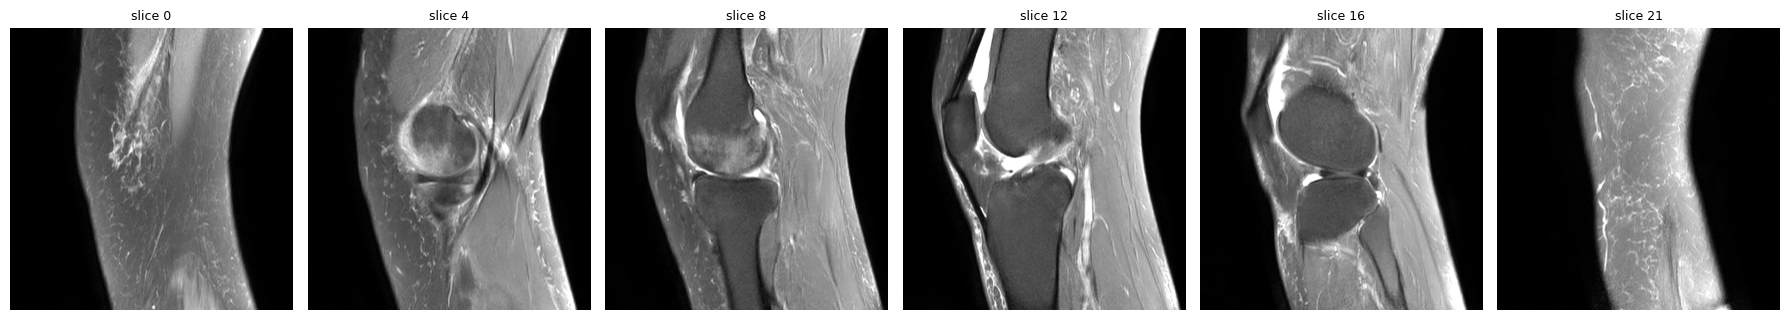

In [27]:
def load_series_volume(series_dir, normalize=True):
    """
    -> (n_slices, H, W) float32, ordered along the through-plane axis.

    Applies RescaleSlope/Intercept, inverts MONOCHROME1, drops off-shape slices,
    and normalises per series (intensities are not comparable across scanners).
    Compressed transfer syntaxes need pylibjpeg or gdcm.
    """
    import pydicom

    files = sorted(glob.glob(os.path.join(series_dir, "*.dcm")))
    if not files:
        raise FileNotFoundError(series_dir)

    def key(ds):
        iop, ipp = getattr(ds, "ImageOrientationPatient", None), getattr(ds, "ImagePositionPatient", None)
        if iop is not None and ipp is not None:
            n = np.cross(np.array(iop[:3], float), np.array(iop[3:], float))
            return float(np.dot(np.array(ipp, float), n))
        return float(getattr(ds, "InstanceNumber", 0) or 0)

    sl = []
    for f in files:
        ds = pydicom.dcmread(f)
        a = ds.pixel_array.astype(np.float32)
        m, b = float(getattr(ds, "RescaleSlope", 1) or 1), float(getattr(ds, "RescaleIntercept", 0) or 0)
        if (m, b) != (1.0, 0.0):
            a = a * m + b
        if getattr(ds, "PhotometricInterpretation", "") == "MONOCHROME1":
            a = a.max() - a
        sl.append((key(ds), a))

    sl.sort(key=lambda t: t[0])
    shapes = [s[1].shape for s in sl]
    modal = max(set(shapes), key=shapes.count)
    vol = np.stack([s[1] for s in sl if s[1].shape == modal]).astype(np.float32)

    if normalize:
        lo, hi = np.percentile(vol, [1, 99])
        vol = np.clip((vol - lo) / (hi - lo), 0, 1) if hi > lo else np.zeros_like(vol)
    return vol


ex = train_series[train_series["exists"]].iloc[0]
vol = load_series_volume(ex["series_dir"])
print(f"{ex['Anatomical_Plane']} | fluid={ex['Fluid_Sensitive']} fatsat={ex['Fat_Suppression']}"
      f" -> {vol.shape}, range [{vol.min():.2f}, {vol.max():.2f}]")

import matplotlib.pyplot as plt
idx = np.linspace(0, len(vol) - 1, 6).astype(int)
fig, axes = plt.subplots(1, 6, figsize=(18, 3.2))
for ax, i in zip(axes, idx):
    ax.imshow(vol[i], cmap="gray"); ax.set_title(f"slice {i}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

In [28]:
print(pd.DataFrame({
    "pseudo_pos": (pseudo[LABEL_COLS] >= 0.5).mean().round(3),
    "pseudo_mean": pseudo[LABEL_COLS].mean().round(3),
    "gold_pos": labeled[LABEL_COLS].mean().round(3),
}).to_string())

                  pseudo_pos  pseudo_mean  gold_pos
ACL                    0.154        0.162     0.414
MCL                    0.135        0.140     0.155
Medial Meniscus        0.381        0.390     0.448
Lateral Meniscus       0.134        0.141     0.397
Medial OA              0.361        0.364     0.259
Lateral OA             0.224        0.227     0.190
PF OA                  0.439        0.446     0.362
Effusion               0.581        0.581     0.603
Synovitis              0.218        0.227     0.466
Baker's                0.250        0.251     0.207
Contusion              0.138        0.144     0.328
Fracture               0.062        0.067     0.310
